**ENTRENAMIENTO DEL DETECTOR DE MATRÍCULAS CON RT-DETRv2**

En este cuaderno se describe cómo se entrenó el detector de matrículas con RT-DETRv2 (`best.pth`) que se utiliza después en el cuaderno de lectura y seguimiento en vídeo.

El flujo de trabajo se estructura en:
1. **Configuración inicial**: Rutas, pesos preentrenados, dispositivo (GPU/CPU) y directorio de resultados.
2. **Entrenamiento**: *Fine-tuning* de `rtdetrv2_r18vd` (preentrenado en COCO) sobre el conjunto de matrículas, con una única clase (`plate`).
3. **Evaluación**: Curvas de AP/AP50/AP75 y pérdida por época, junto con gráficas adicionales de progreso y las métricas COCO finales.
4. **Validación del mejor modelo**: Evaluación de `best.pth` sobre el conjunto de validación.
5. **Prueba de inferencia**: Lote de imágenes de validación con las cajas reales y las predichas.

Todas las gráficas y el lote de imágenes se guardan en el directorio `RT-DETR_resultado_entrenamiento`.

**CONFIGURACIÓN INICIAL: RUTAS Y PESOS PREENTRENADOS**

Se definen las rutas del fichero de configuración, de la carpeta de salida del entrenamiento y de los pesos de partida. Si los pesos no existen, se descargan de GitHub (`rtdetrv2_r18vd_120e_coco_rerun_48.1.pth`).

Además se crea (si no existe) el directorio `RT-DETR_resultado_entrenamiento`, donde se guardarán las gráficas y las imágenes de resultados.

In [1]:
import os
import sys
import subprocess
import urllib.request
import torch
from pathlib import Path

# =====================================================
# DIRECTORIO DE RESULTADOS (se crea si no existe)
# =====================================================

RESULTS_DIR = Path("RT-DETR_resultado_entrenamiento").resolve()
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("Directorio de resultados:", RESULTS_DIR)

# =====================================================
# PESOS PREENTRENADOS
# =====================================================


PRETRAINED_URL = (
    "https://github.com/lyuwenyu/storage/releases/download/"
    "v0.2/rtdetrv2_r18vd_120e_coco_rerun_48.1.pth"
)

CONFIG = Path("RT-DETR/rtdetrv2_pytorch/configs/rtdetrv2/rtdetrv2_r18vd_120e_plates.yml").resolve()
OUTPUT_DIR = Path("RT-DETR/rtdetrv2_pytorch/output/rtdetrv2_r18vd_120e_plate").resolve()
PRETRAINED = Path("RT-DETR/rtdetrv2_pytorch/output/rtdetrv2_r18vd_120e_plate/best.pth").resolve()
RTDETR_PATH = os.path.abspath("RT-DETR/rtdetrv2_pytorch")

if not PRETRAINED.exists():

    print("Descargando pesos preentrenados...")

    urllib.request.urlretrieve(
        PRETRAINED_URL,
        PRETRAINED
    )

print("Pesos descargados:", PRETRAINED)


DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Dispositivo:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Directorio de resultados: C:\Users\vidal\OneDrive\Escritorio\UNI\4ano\VC\Practicas_VC\P4\RT-DETR_resultado_entrenamiento
Pesos descargados: C:\Users\vidal\OneDrive\Escritorio\UNI\4ano\VC\Practicas_VC\P4\RT-DETR\rtdetrv2_pytorch\output\rtdetrv2_r18vd_120e_plate\best.pth
Dispositivo: cuda
GPU: NVIDIA GeForce RTX 3070


**ENTRENAMIENTO DEL MODELO**

La función `run_training` lanza `tools/train.py` del repositorio RT-DETR como subproceso, usando la configuración `rtdetrv2_r18vd_120e_plates.yml`. Los aspectos principales son:
- **`--use-amp`**: Entrenamiento con precisión mixta para reducir el uso de memoria y acelerar el proceso.
- **`--seed=0`**: Semilla fija para que el entrenamiento sea reproducible.
- **`-t`**: Pesos de partida para el *fine-tuning* (checkpoint preentrenado en COCO).
- **`-r`**: Permite reanudar un entrenamiento interrumpido desde `last.pth`.

La salida del entrenamiento se muestra en directo en el cuaderno.

In [8]:
# =====================================================
# ENTRENAMIENTO
# =====================================================

def run_training(resume=None):

    cmd = [
        sys.executable,
        "tools/train.py",
        "-c", str(CONFIG),
        "--use-amp",
        "--seed=0"
    ]

    if resume is not None:
        cmd += ["-r", str(resume)]

    else:

        cmd += ["-t", str(PRETRAINED)]

    env = os.environ.copy()

    env["CUDA_VISIBLE_DEVICES"] = "0"
    env["PYTHONUNBUFFERED"] = "1"

    print("\nIniciando entrenamiento RT-DETRv2...")
    print("Configuración:", CONFIG)
    print("Pesos iniciales:", PRETRAINED)

    process = subprocess.Popen(
        cmd,
        cwd=str(RTDETR_PATH),
        env=env,
        text=True,
        bufsize=1,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT
    )

    for line in process.stdout:
        print(line, end="")

    process.wait()

    if process.returncode != 0:
        raise RuntimeError(
            f"Error durante el entrenamiento: {process.returncode}"
        )

    print("\nEntrenamiento finalizado correctamente.")

**EJECUCIÓN DEL ENTRENAMIENTO**

Se lanza el entrenamiento. La primera línea (comentada) inicia un entrenamiento desde los pesos preentrenados; la segunda reanuda el entrenamiento desde el último checkpoint (`last.pth`).

In [9]:
# =====================================================
# EJECUTAR
# =====================================================

run_training()

# Para reanudar un entrenamiento interrumpido:
#run_training(resume=OUTPUT_DIR / "last.pth")


Iniciando entrenamiento RT-DETRv2...
Configuración: C:\Users\vidal\OneDrive\Escritorio\UNI\4ano\VC\Practicas_VC\P4\RT-DETR\rtdetrv2_pytorch\configs\rtdetrv2\rtdetrv2_r18vd_120e_plates.yml
Pesos iniciales: C:\Users\vidal\OneDrive\Escritorio\UNI\4ano\VC\Practicas_VC\P4\RT-DETR\rtdetrv2_pytorch\output\rtdetrv2_r18vd_120e_plate\best.pth
Not init distributed mode.
cfg:  {'task': 'detection', '_model': None, '_postprocessor': None, '_criterion': None, '_optimizer': None, '_lr_scheduler': None, '_lr_warmup_scheduler': None, '_train_dataloader': None, '_val_dataloader': None, '_ema': None, '_scaler': None, '_train_dataset': None, '_val_dataset': None, '_collate_fn': None, '_evaluator': None, '_writer': None, 'num_workers': 0, 'batch_size': None, '_train_batch_size': None, '_val_batch_size': None, '_train_shuffle': None, '_val_shuffle': None, 'resume': None, 'tuning': 'C:\\Users\\vidal\\OneDrive\\Escritorio\\UNI\\4ano\\VC\\Practicas_VC\\P4\\RT-DETR\\rtdetrv2_pytorch\\output\\rtdetrv2_r18vd_120

**EVALUACIÓN DEL MODELO ENTRENADO**

Se leen las métricas de evaluación COCO por época desde `log.txt`. Si el entrenamiento se reanudó, una misma época puede aparecer repetida, por lo que se conserva la última aparición de cada una. Se obtienen:
- **AP (0.50:0.95)**: Precisión media promediada entre IoU 0.5 y 0.95.
- **AP50 / AP75**: Precisión media con IoU de 0.5 y 0.75, respectivamente.
- **AR**: Recall medio para distintos números máximos de detecciones y tamaños de objeto.

Se muestra la gráfica principal de AP por época junto con la pérdida de entrenamiento y se guarda en `RT-DETR_resultado_entrenamiento`.

In [10]:
import json
import matplotlib.pyplot as plt

LOG_FILE = OUTPUT_DIR / "log.txt"

rows = [
    json.loads(line)
    for line in open(LOG_FILE, encoding="utf-8")
    if line.strip()
]

# Filtrar épocas que contienen evaluación COCO
# Si se reanudó el entrenamiento, una misma época puede aparecer repetida:
# nos quedamos con la última aparición de cada una (esto era lo que ensuciaba la gráfica)
by_epoch = {}
for r in rows:
    if "test_coco_eval_bbox" in r:
        by_epoch[r["epoch"]] = r

epochs = sorted(by_epoch)
valid_rows = [by_epoch[e] for e in epochs]

# Orden de las métricas COCO en test_coco_eval_bbox
METRIC_NAMES = [
    "AP (0.50:0.95)", "AP50", "AP75",
    "AP small", "AP medium", "AP large",
    "AR@1", "AR@10", "AR@100",
    "AR small", "AR medium", "AR large",
]

ap   = [r["test_coco_eval_bbox"][0] for r in valid_rows]
ap50 = [r["test_coco_eval_bbox"][1] for r in valid_rows]
ap75 = [r["test_coco_eval_bbox"][2] for r in valid_rows]
loss = [r.get("train_loss") for r in valid_rows]

best = max(range(len(ap)), key=lambda i: ap[i])

**GRÁFICAS ADICIONALES DEL PROGRESO DEL ENTRENAMIENTO**

Se generan cuatro gráficas complementarias a partir de `log.txt`, guardadas en `RT-DETR_resultado_entrenamiento/progreso_entrenamiento.png`:
- **AP por tamaño de objeto**: Evolución de AP en objetos pequeños, medianos y grandes (las matrículas pequeñas son el caso más difícil).
- **Recall medio (AR)**: Evolución de AR@1, AR@10 y AR@100.
- **Componentes de la pérdida**: Pérdida total junto con las pérdidas de clasificación (VFL), de caja (L1) y de GIoU, si están en el log.
- **Tasa de aprendizaje y mejora de AP**: Evolución del *learning rate* y de la mejora de AP respecto a la primera época.

También se guarda la tabla completa de métricas por época en `metricas_por_epoca.csv`.

Imágenes: 400 | GT: 967 | detecciones (conf>=0.001): 120000


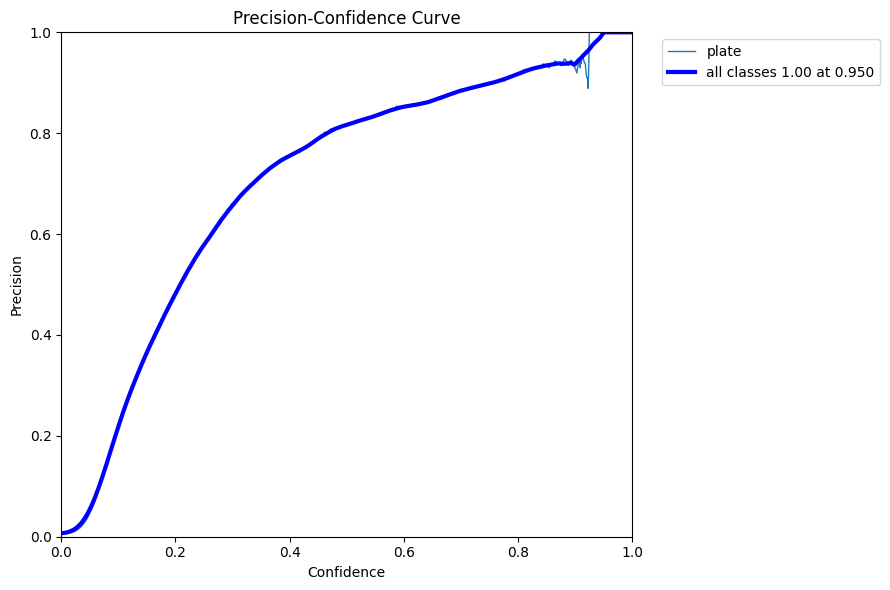

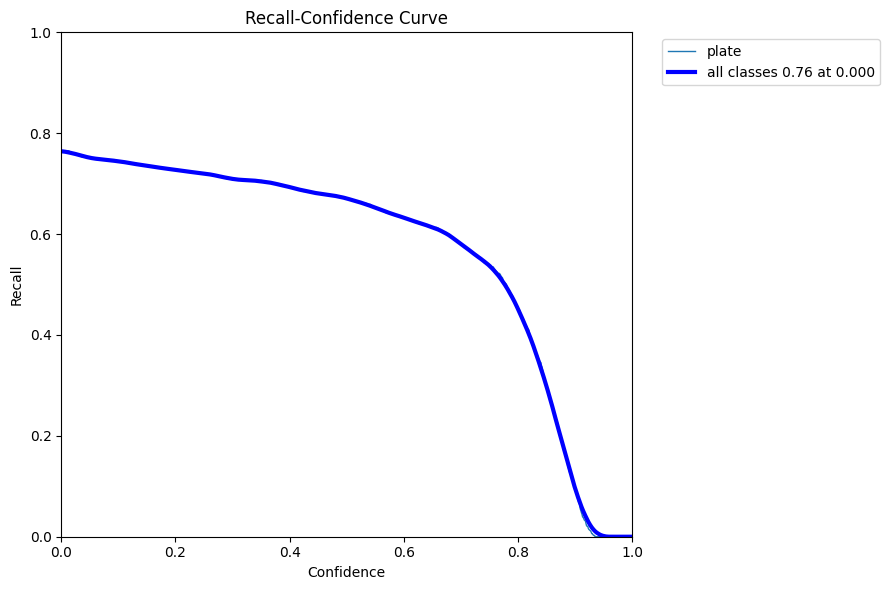

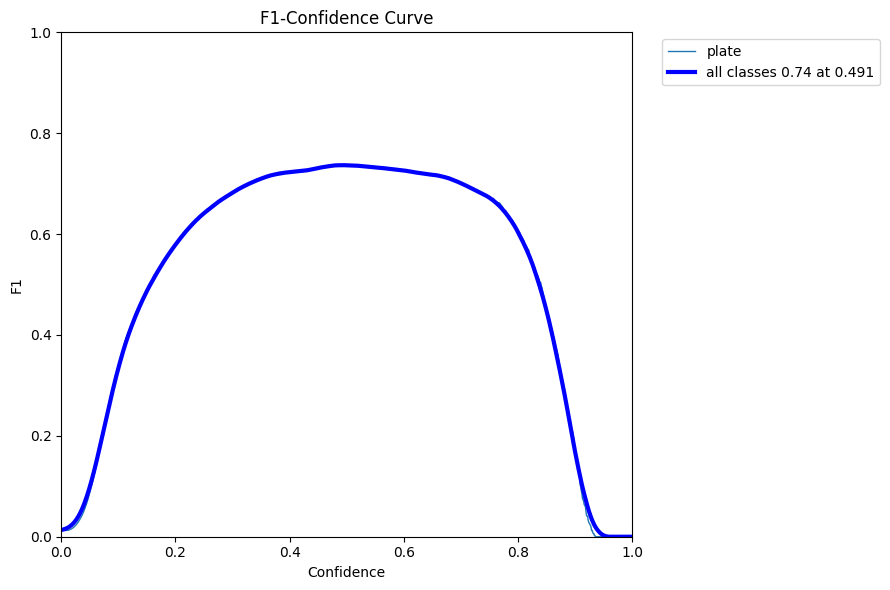

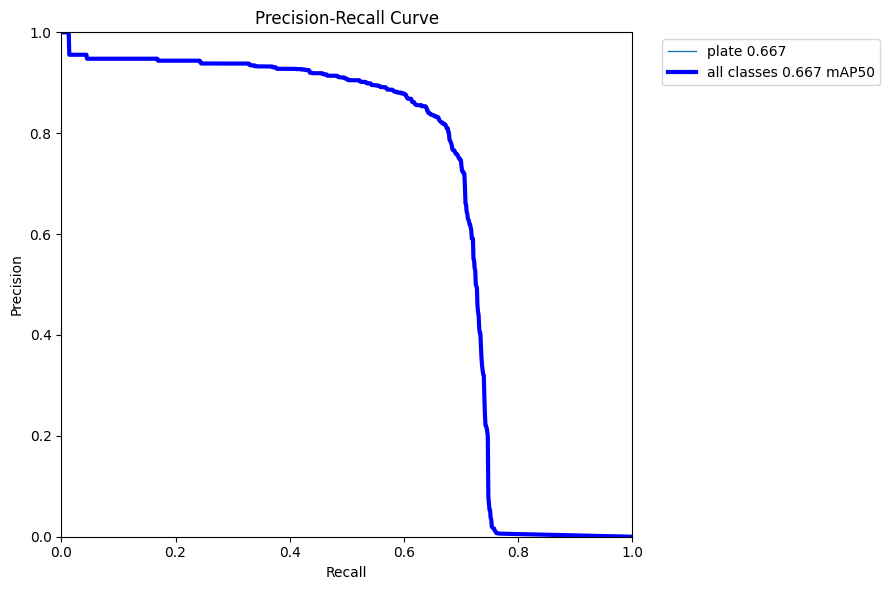

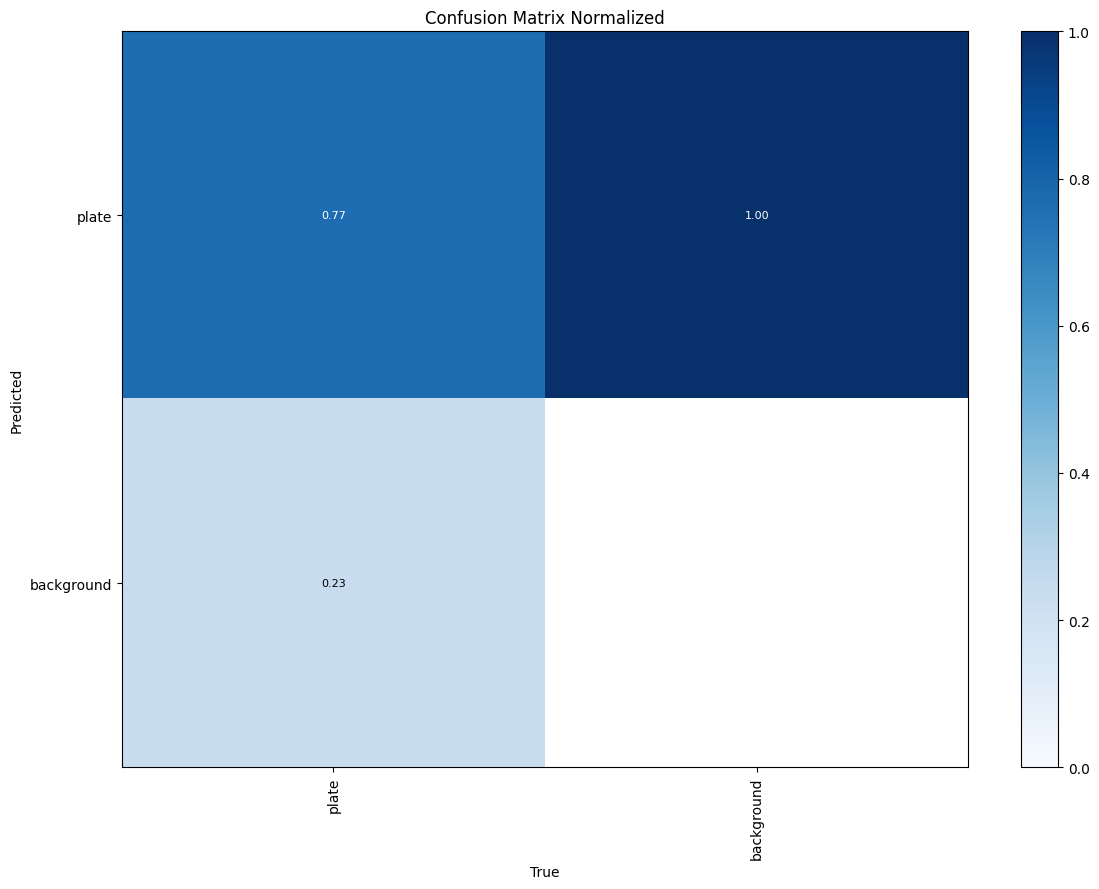

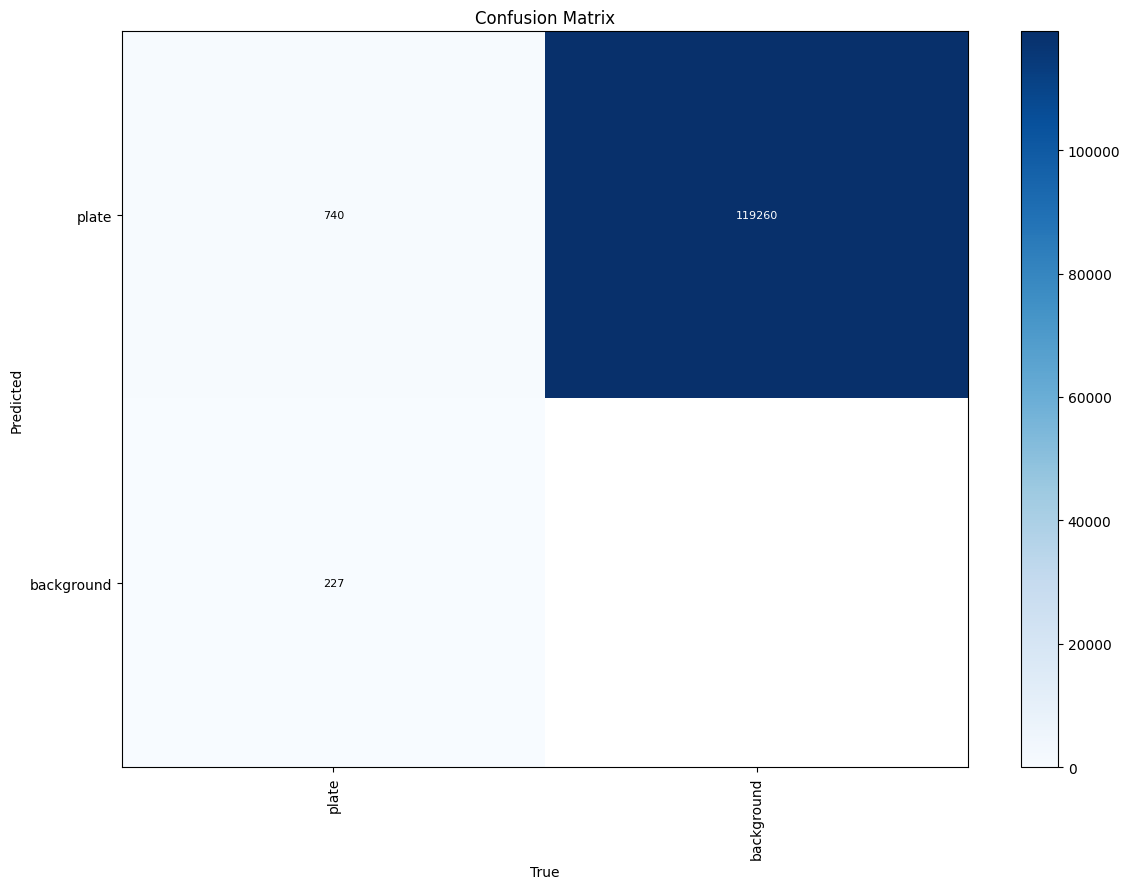

mAP50: 0.667
Mejor F1 suavizado: 0.74 con confianza 0.491
Matriz (conf>=0.001): TP=740 | FP=119260 | FN=227
Gráficas guardadas en: C:\Users\vidal\OneDrive\Escritorio\UNI\4ano\VC\Practicas_VC\P4\RT-DETR_resultado_entrenamiento


In [11]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

# ---------- Parámetros ----------
NOMBRES = ["plate"]
CONF_EVAL = 0.001      # confianza mínima de las detecciones que se recogen
CONF_MATRIX = 0.001    # umbral de confianza para la matriz de confusión
                       # (0.001 reproduce el PDF; con 0.25-0.4 la matriz es más realista)
IOU_THR = 0.5          # IoU para considerar una detección como acierto (TP)
BATCH = 16

# ---------- Utilidades ----------
def iou_matriz(a, b):
    """IoU entre dos conjuntos de cajas xyxy -> matriz (len(a), len(b))."""
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)

def emparejar(boxes, scores, gt, thr=IOU_THR):
    """Emparejado voraz por confianza descendente. Devuelve scores ordenados y flags TP."""
    orden = np.argsort(-scores)
    tp = np.zeros(len(boxes), dtype=bool)
    if len(gt) == 0 or len(boxes) == 0:
        return scores[orden], tp
    iou = iou_matriz(boxes[orden], gt)
    usado = np.zeros(len(gt), dtype=bool)
    for k in range(len(orden)):
        cand = np.where(~usado, iou[k], -1.0)
        j = cand.argmax()
        if cand[j] >= thr:
            usado[j] = True
            tp[k] = True
    return scores[orden], tp

def smooth(y, f=0.05):
    """Suavizado por media móvil (igual que Ultralytics)."""
    nf = round(len(y) * f * 2) // 2 + 1
    p = np.ones(nf // 2)
    yp = np.concatenate((p * y[0], y, p * y[-1]), 0)
    return np.convolve(yp, np.ones(nf) / nf, mode="valid")

# ---------- 1) Inferencia sobre todo el conjunto de validación ----------
gt_por_img = {}
for a in coco["annotations"]:
    if a.get("iscrowd", 0):
        continue
    x, y, w, h = a["bbox"]
    gt_por_img.setdefault(a["image_id"], []).append([x, y, x + w, y + h])

imgs = coco["images"]
todas_scores, todos_tp, n_gt = [], [], 0

for i in range(0, len(imgs), BATCH):
    lote = imgs[i:i + BATCH]
    xs, sizes = [], []
    for info in lote:
        im = Image.open(IMG_DIR / info["file_name"]).convert("RGB")
        sizes.append([im.width, im.height])
        im = im.resize((640, 640), Image.BILINEAR)
        xs.append(torch.from_numpy(np.array(im)).permute(2, 0, 1).float().div(255))

    x = torch.stack(xs).to(DEVICE)
    size = torch.tensor(sizes, device=DEVICE)
    with torch.no_grad():
        _, boxes, scores = detector(x, size)
    boxes, scores = boxes.cpu().numpy(), scores.cpu().numpy()

    for info, b, s in zip(lote, boxes, scores):
        keep = s >= CONF_EVAL
        b, s = b[keep], s[keep]
        gt = np.array(gt_por_img.get(info["id"], []), dtype=float).reshape(-1, 4)
        n_gt += len(gt)
        s_ord, tp = emparejar(b, s, gt)
        todas_scores.append(s_ord)
        todos_tp.append(tp)

todas_scores = np.concatenate(todas_scores)
todos_tp = np.concatenate(todos_tp)
print(f"Imágenes: {len(imgs)} | GT: {n_gt} | detecciones (conf>={CONF_EVAL}): {len(todas_scores)}")

# ---------- 2) Curvas P / R / F1 frente a la confianza ----------
px = np.linspace(0, 1, 1000)
asc = np.argsort(todas_scores)
s_asc, tp_asc = todas_scores[asc], todos_tp[asc]
suf_tp = np.concatenate([np.cumsum(tp_asc[::-1])[::-1], [0]])   # TP con score >= t

idx = np.searchsorted(s_asc, px, side="left")
n_pred = len(s_asc) - idx
tp_n = suf_tp[idx]

P = np.where(n_pred > 0, tp_n / np.maximum(n_pred, 1), 1.0)
R = tp_n / max(n_gt, 1)
F1 = 2 * P * R / (P + R + 1e-16)

def plot_curva_conf(y, ylabel, titulo, fichero):
    fig, ax = plt.subplots(figsize=(9, 6), tight_layout=True)
    ax.plot(px, y, linewidth=1, label=NOMBRES[0])
    ys = smooth(y, 0.05)
    ax.plot(px, ys, linewidth=3, color="blue",
            label=f"all classes {ys.max():.2f} at {px[ys.argmax()]:.3f}")
    ax.set_xlabel("Confidence")
    ax.set_ylabel(ylabel)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_title(titulo)
    ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left")
    fig.savefig(RESULTS_DIR / fichero, dpi=250)
    plt.show()
    return ys

P_s  = plot_curva_conf(P,  "Precision", "Precision-Confidence Curve", "P_curve.png")
R_s  = plot_curva_conf(R,  "Recall",    "Recall-Confidence Curve",    "R_curve.png")
F1_s = plot_curva_conf(F1, "F1",        "F1-Confidence Curve",        "F1_curve.png")

# ---------- 3) Curva Precision-Recall ----------
orden = np.argsort(-todas_scores)
tpc = np.cumsum(todos_tp[orden])
fpc = np.cumsum(~todos_tp[orden])
recall = tpc / max(n_gt, 1)
precision = tpc / (tpc + fpc + 1e-16)

mrec = np.concatenate(([0.0], recall, [1.0]))
mpre = np.concatenate(([1.0], precision, [0.0]))
mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))        # envolvente de precisión
trapz = getattr(np, "trapezoid", None) or np.trapz
x101 = np.linspace(0, 1, 101)
ap50 = trapz(np.interp(x101, mrec, mpre), x101)
py = np.interp(px, mrec, mpre)

fig, ax = plt.subplots(figsize=(9, 6), tight_layout=True)
ax.plot(px, py, linewidth=1, label=f"{NOMBRES[0]} {ap50:.3f}")
ax.plot(px, py, linewidth=3, color="blue", label=f"all classes {ap50:.3f} mAP50")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("Precision-Recall Curve")
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left")
fig.savefig(RESULTS_DIR / "PR_curve.png", dpi=250)
plt.show()

# ---------- 4) Matrices de confusión ----------
mask = todas_scores >= CONF_MATRIX
tp_c = int(todos_tp[mask].sum())
fp_c = int(mask.sum()) - tp_c
fn_c = n_gt - tp_c
# filas = predicho (plate, background) | columnas = real (plate, background)
matriz = np.array([[tp_c, fp_c],
                   [fn_c, 0]], dtype=float)

def plot_matriz(m, normalizar, fichero):
    arr = m / (m.sum(0, keepdims=True) + 1e-9) if normalizar else m.copy()
    arr[arr < 0.005] = np.nan
    etiquetas = NOMBRES + ["background"]

    cmap = plt.get_cmap("Blues").copy()
    cmap.set_bad("white")
    fig, ax = plt.subplots(figsize=(12, 9))
    im = ax.imshow(arr, cmap=cmap, vmin=0.0, aspect="auto")
    fig.colorbar(im, ax=ax)

    vmax = np.nanmax(arr)
    for r in range(arr.shape[0]):
        for c in range(arr.shape[1]):
            if not np.isnan(arr[r, c]):
                txt = f"{arr[r, c]:.2f}" if normalizar else f"{arr[r, c]:.0f}"
                ax.text(c, r, txt, ha="center", va="center", fontsize=8,
                        color="white" if arr[r, c] > 0.5 * vmax else "black")

    ax.set_xticks(range(len(etiquetas)))
    ax.set_yticks(range(len(etiquetas)))
    ax.set_xticklabels(etiquetas, rotation=90)
    ax.set_yticklabels(etiquetas)
    ax.set_xlabel("True")
    ax.set_ylabel("Predicted")
    ax.set_title("Confusion Matrix Normalized" if normalizar else "Confusion Matrix")
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / fichero, dpi=250)
    plt.show()

plot_matriz(matriz, True,  "confusion_matrix_normalized.png")
plot_matriz(matriz, False, "confusion_matrix.png")

# ---------- Resumen ----------
i_f1 = F1_s.argmax()
print(f"mAP50: {ap50:.3f}")
print(f"Mejor F1 suavizado: {F1_s[i_f1]:.2f} con confianza {px[i_f1]:.3f}")
print(f"Matriz (conf>={CONF_MATRIX}): TP={tp_c} | FP={fp_c} | FN={fn_c}")
print("Gráficas guardadas en:", RESULTS_DIR)

**VALIDACIÓN DEL MEJOR MODELO**

La función `run_validation` evalúa unos pesos concretos sobre el conjunto de validación ejecutando `tools/train.py` con `--test-only`. Se evalúa `best.pth`, que corresponde a la época con mejor AP.

In [6]:
def run_validation(weights):

    cmd = [
        sys.executable,
        "tools/train.py",
        "-c", str(CONFIG),
        "-r", str(weights),
        "--test-only"
    ]

    env = os.environ.copy()
    env["CUDA_VISIBLE_DEVICES"] = "0"
    env["PYTHONUNBUFFERED"] = "1"

    process = subprocess.Popen(
        cmd,
        cwd=str(RTDETR_PATH),
        env=env,
        text=True,
        bufsize=1,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT
    )

    for line in process.stdout:
        print(line, end="")

    process.wait()

    if process.returncode != 0:
        raise RuntimeError("Error durante la validación")

    print("\nValidación completada.")


# Evaluar best.pth
run_validation(OUTPUT_DIR / "best.pth")

Not init distributed mode.
cfg:  {'task': 'detection', '_model': None, '_postprocessor': None, '_criterion': None, '_optimizer': None, '_lr_scheduler': None, '_lr_warmup_scheduler': None, '_train_dataloader': None, '_val_dataloader': None, '_ema': None, '_scaler': None, '_train_dataset': None, '_val_dataset': None, '_collate_fn': None, '_evaluator': None, '_writer': None, 'num_workers': 0, 'batch_size': None, '_train_batch_size': None, '_val_batch_size': None, '_train_shuffle': None, '_val_shuffle': None, 'resume': 'C:\\Users\\vidal\\OneDrive\\Escritorio\\UNI\\4ano\\VC\\Practicas_VC\\P4\\RT-DETR\\rtdetrv2_pytorch\\output\\rtdetrv2_r18vd_120e_plate\\best.pth', 'tuning': '../../weights/rtdetrv2_r18vd_120e_coco_rerun_48.1.pth', 'epoches': 24, 'last_epoch': -1, 'use_amp': False, 'use_ema': True, 'ema_decay': 0.9999, 'ema_warmups': 2000, 'sync_bn': True, 'clip_max_norm': 0.1, 'find_unused_parameters': False, 'seed': None, 'print_freq': 10, 'checkpoint_freq': 10, 'output_dir': './output/rtde

**PRUEBA DE INFERENCIA: LOTE DE IMÁGENES DE VALIDACIÓN**

Como comprobación final se carga `best.pth` (pesos EMA) con la misma configuración del entrenamiento y se ejecuta el detector sobre un lote de imágenes del conjunto de validación, con un umbral de confianza de 0.3 y la misma resolución que en el entrenamiento (640x640). En cada imagen se dibujan:
- **Cajas reales (verde)**: Anotaciones del conjunto de validación.
- **Cajas predichas (rojo)**: Detecciones del modelo junto con su confianza.

El lote se guarda en `RT-DETR_resultado_entrenamiento/lote_validacion.png`.

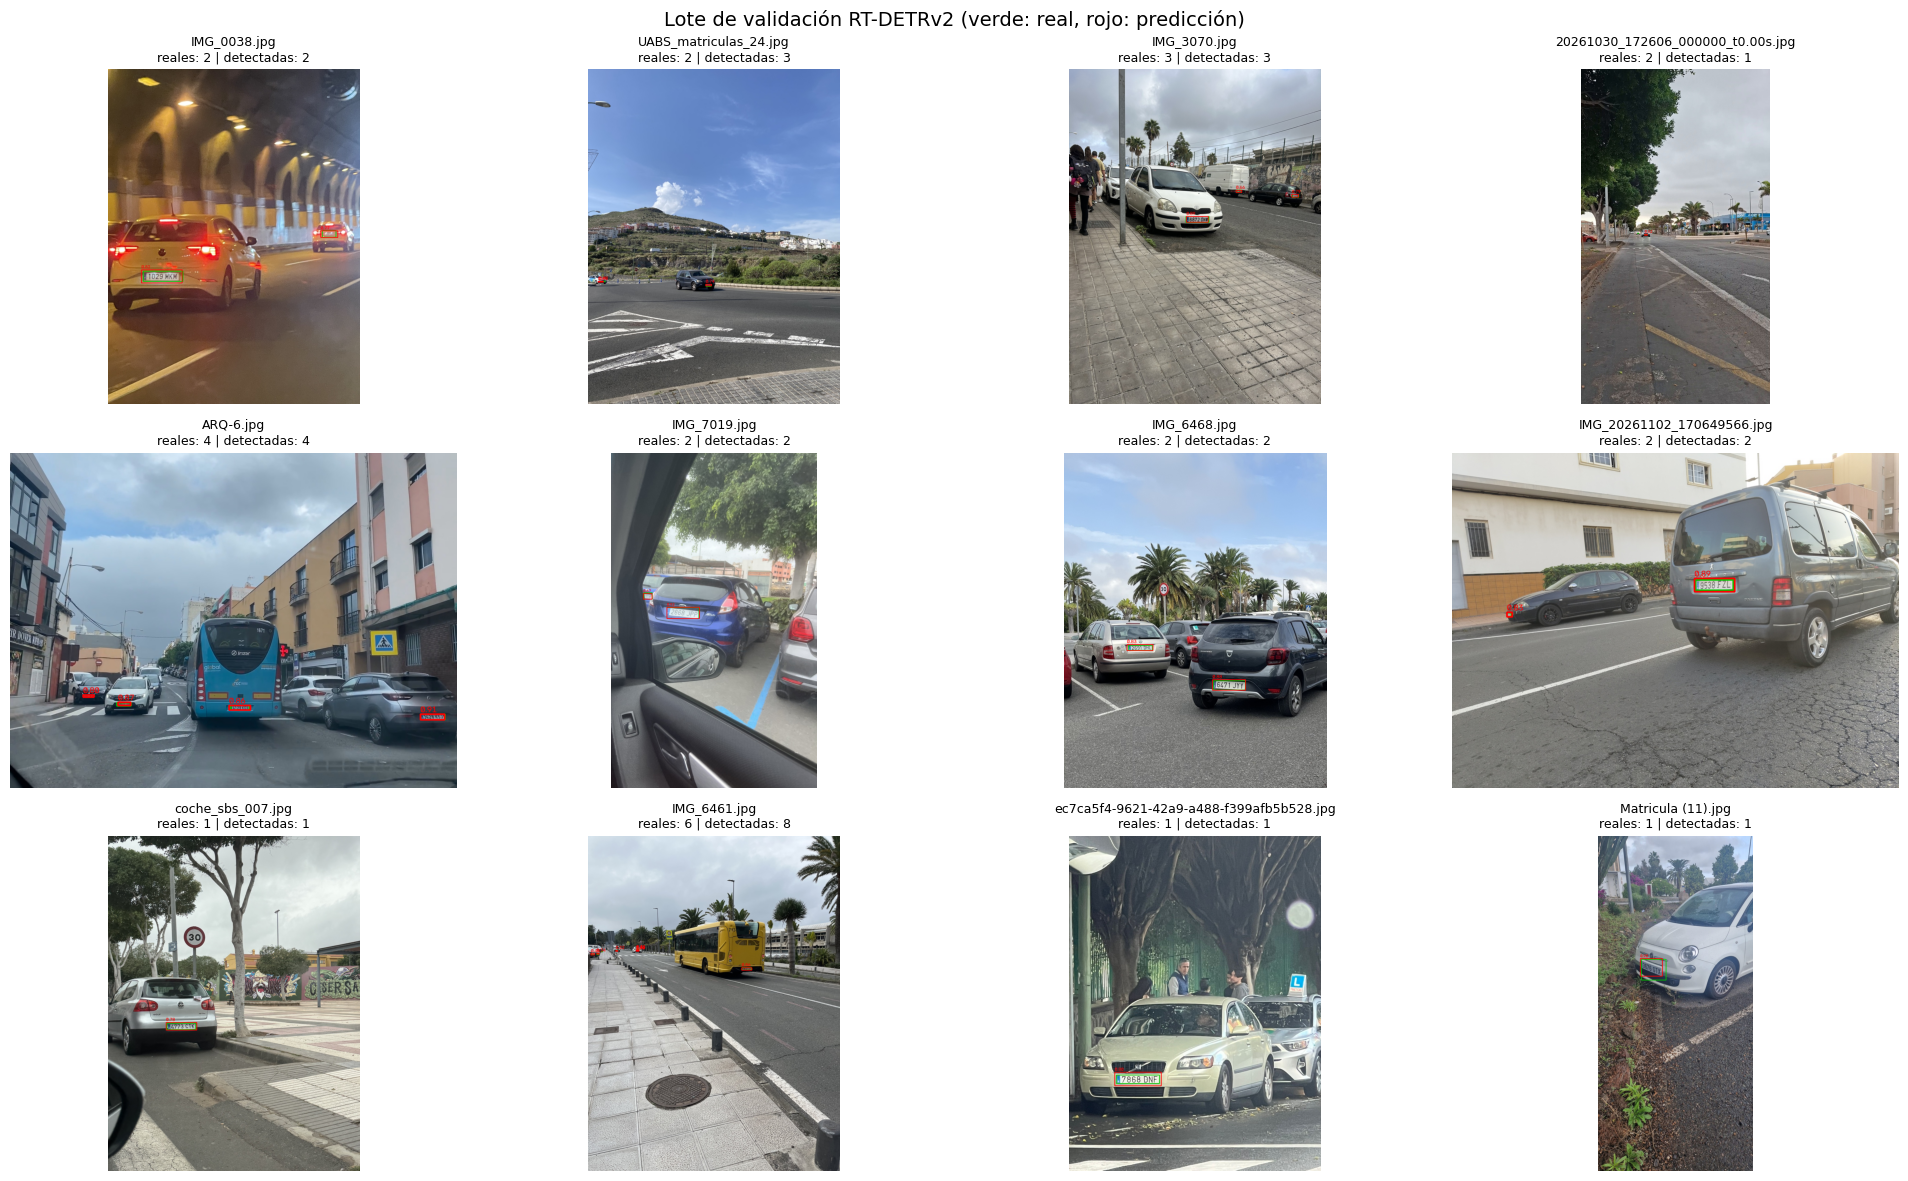

Lote de imágenes guardado en: C:\Users\vidal\OneDrive\Escritorio\UNI\4ano\VC\Practicas_VC\P4\RT-DETR_resultado_entrenamiento\lote_validacion.png


In [12]:
import random
import numpy as np
import cv2
from PIL import Image

if RTDETR_PATH not in sys.path:
    sys.path.insert(0, RTDETR_PATH)

from src.core import YAMLConfig

# Parámetros del lote de imágenes
N_IMAGENES = 12      # imágenes del lote
CONF_MIN = 0.3       # confianza mínima de las detecciones mostradas
COLUMNAS = 4

# Rutas del dataset (relativas a rtdetrv2_pytorch, igual que en el .yml)
DATASET_DIR = (Path(RTDETR_PATH) / ".." / ".." / "plates" / "coco-dataset").resolve()
IMG_DIR = DATASET_DIR / "images"
VAL_JSON = DATASET_DIR / "annotations" / "instances_val.json"

# ---------- Carga del mejor modelo ----------
cfg = YAMLConfig(str(CONFIG), resume=str(OUTPUT_DIR / "best.pth"))

checkpoint = torch.load(OUTPUT_DIR / "best.pth", map_location="cpu")
state = checkpoint["ema"]["module"] if "ema" in checkpoint else checkpoint["model"]
cfg.model.load_state_dict(state)

class ModeloDeploy(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.model = cfg.model.deploy()
        self.postprocessor = cfg.postprocessor.deploy()

    def forward(self, images, orig_target_sizes):
        outputs = self.model(images)
        return self.postprocessor(outputs, orig_target_sizes)

detector = ModeloDeploy().to(DEVICE).eval()

# ---------- Selección del lote de imágenes ----------
with open(VAL_JSON, encoding="utf-8") as f:
    coco = json.load(f)

anotaciones = {}
for ann in coco["annotations"]:
    anotaciones.setdefault(ann["image_id"], []).append(ann["bbox"])   # bbox COCO: x, y, w, h

random.seed(0)
imagenes = random.sample(coco["images"], min(N_IMAGENES, len(coco["images"])))

# ---------- Inferencia y dibujado ----------
resultados = []
for info in imagenes:
    bgr = cv2.imread(str(IMG_DIR / info["file_name"]))
    if bgr is None:
        continue
    h, w = bgr.shape[:2]
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

    # mismo preprocesado que en validación: resize a 640x640 y normalización 0-1
    im = Image.fromarray(rgb).resize((640, 640), Image.BILINEAR)
    x = torch.from_numpy(np.array(im)).permute(2, 0, 1).float().div(255)[None].to(DEVICE)
    size = torch.tensor([[w, h]], device=DEVICE)

    with torch.no_grad():
        labels, boxes, scores = detector(x, size)
    boxes, scores = boxes[0].cpu().numpy(), scores[0].cpu().numpy()
    keep = scores >= CONF_MIN
    boxes, scores = boxes[keep], scores[keep]

    # cajas reales en verde
    for bx, by, bw, bh in anotaciones.get(info["id"], []):
        cv2.rectangle(rgb, (int(bx), int(by)), (int(bx + bw), int(by + bh)), (0, 200, 0), max(2, w // 400))

    # cajas predichas en rojo
    for (x1, y1, x2, y2), s in zip(boxes, scores):
        cv2.rectangle(rgb, (int(x1), int(y1)), (int(x2), int(y2)), (255, 0, 0), max(2, w // 400))
        cv2.putText(rgb, f"{s:.2f}", (int(x1), max(15, int(y1) - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX, max(0.5, w / 1600), (255, 0, 0), max(1, w // 800))

    resultados.append((rgb, info["file_name"], len(boxes), len(anotaciones.get(info["id"], []))))

# ---------- Rejilla de resultados ----------
filas = int(np.ceil(len(resultados) / COLUMNAS))
fig, axs = plt.subplots(filas, COLUMNAS, figsize=(5 * COLUMNAS, 4 * filas), squeeze=False)

for ax in axs.ravel():
    ax.axis("off")
for ax, (img, nombre, n_pred, n_real) in zip(axs.ravel(), resultados):
    ax.imshow(img)
    ax.set_title(f"{nombre}\nreales: {n_real} | detectadas: {n_pred}", fontsize=9)

plt.suptitle("Lote de validación RT-DETRv2 (verde: real, rojo: predicción)", fontsize=14)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "lote_validacion.png", dpi=150, bbox_inches="tight")
plt.show()

print("Lote de imágenes guardado en:", RESULTS_DIR / "lote_validacion.png")